# FlowState Δ — Chapter 6: Liquid Time-Constant Networks

**Research lab notebook | Curriculum v2.0 | Chapter 6**

**Status:** introductory implementation + empirical checks. This is **not** a faithful reproduction of the full [Hasani et al. LTC architecture](https://arxiv.org/abs/2006.04439). That broader reproduction belongs to Chapter 8.

### Research question
How can input- and state-dependent gates change continuous-time recurrent dynamics, and how do training and numerical integration affect the resulting behavior?

**You will:** (1) verify a scalar LTC-style update by hand, (2) visualize input-dependent time constants, (3) train using BPTT, (4) test on new pulse patterns, (5) challenge the model with a simpler baseline, and (6) compare Euler and RK4 numerical stability.

**Exit criteria:** every assertion passes; training and test error are recorded; plots are saved; numerical stability and accuracy are distinguished; conclusions do not overclaim model novelty or generalization.

## 0. Environment and reproducibility

Run on **CPU**: this lab is too small to benefit reliably from GPU acceleration. Run the entire notebook top-to-bottom in a Python environment with `torch`, `numpy`, `matplotlib` and `pandas` (pandas is optional in principle, but used for the tables here). Plots and metrics will be saved in `chapter6_outputs/` relative to your notebook working directory.

In [1]:
import math
import platform
from pathlib import Path
import csv

import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
OUT = Path("chapter6_outputs")
OUT.mkdir(exist_ok=True)

print(f"Python: {platform.python_version()} | PyTorch: {torch.__version__}")
print(f"Device: CPU | Seed: {SEED} | Output directory: {OUT.resolve()}")

Python: 3.12.3 | PyTorch: 2.15.0+cu132
Device: CPU | Seed: 42 | Output directory: /home/pratay-karali/Desktop/flowstate/chap-6/chapter6_outputs


## 1. Core mathematical model

For a **scalar educational LTC-style neuron** with hidden state $x(t)$, input $u(t)$, learned target parameter $A$, base time constant $\tau>0$, and nonlinear gate $f(x,u)$:

$$
\dot x=-\frac{x}{\tau}+f(x,u)(A-x),\qquad
f(x,u)=\sigma(w_x x+w_u u+b).
$$

Rearranging suggests an **instantaneous effective coefficient-based time constant**

$$
\tau_{\mathrm{eff}}=\left(\frac{1}{\tau}+f(x,u)\right)^{-1}.
$$

**Caution:** for a state-dependent gate, this is **not** by itself the full local linearized relaxation time; the derivative of $f$ with respect to $x$ matters as well.

An Euler discretization is $x_{n+1}=x_n+\Delta t\,\dot x_n$.

This simplified equation captures key ideas of LTC dynamics but **does not implement the published multi-neuron LTC wiring or its full numerical solver**.

In [2]:
class LiquidNeuron(nn.Module):
    """Educational scalar LTC-style neuron, integrated by forward Euler."""

    def __init__(self):
        super().__init__()
        self.log_tau = nn.Parameter(torch.tensor(math.log(2.0)))
        self.w_x = nn.Parameter(torch.tensor(0.5))
        self.w_u = nn.Parameter(torch.tensor(1.0))
        self.bias = nn.Parameter(torch.tensor(math.log(0.4 / 0.6)))
        self.A = nn.Parameter(torch.tensor(1.0))

    def forward(self, x, u, dt=0.1):
        tau = torch.exp(self.log_tau)  # positivity constraint: tau > 0
        gate = torch.sigmoid(self.w_x * x + self.w_u * u + self.bias)
        dxdt = -x / tau + gate * (self.A - x)
        x_next = x + dt * dxdt
        tau_eff = 1.0 / (1.0 / tau + gate)
        return x_next, gate, tau_eff, dxdt


def rollout(model, input_sequence, dt=0.1):
    """Unroll a recurrent model without detaching hidden state (BPTT-compatible)."""
    x = torch.tensor(0.0)
    states, gates, time_constants, derivatives = [], [], [], []
    for u in input_sequence:
        x, gate, tau_eff, dxdt = model(x, u, dt=dt)
        states.append(x)
        gates.append(gate)
        time_constants.append(tau_eff)
        derivatives.append(dxdt)
    return tuple(torch.stack(v) for v in (states, gates, time_constants, derivatives))


model0 = LiquidNeuron()
print("Trainable scalar parameters:", sum(p.numel() for p in model0.parameters()))

Trainable scalar parameters: 5


## 2. Mathematical sanity check (Chapter 6.1)

Given $x_0=0$, $u_0=0$, $\tau=2$, $f=0.4$, $A=1$, and $\Delta t=0.1$:

$$\dot x_0=0.4,\qquad x_1=0.04,\qquad \tau_{\mathrm{eff}}=2/1.8\approx1.11111.$$

The assertions below verify that our implementation reproduces this hand calculation.

In [3]:
with torch.no_grad():
    x1, gate, tau_eff, dxdt = model0(torch.tensor(0.0), torch.tensor(0.0))

assert abs(dxdt.item() - 0.4) < 1e-6
assert abs(x1.item() - 0.04) < 1e-6
assert abs(tau_eff.item() - (2.0 / 1.8)) < 1e-6
print(f"PASS: dx/dt={dxdt.item():.5f}, x_next={x1.item():.5f}, tau_eff={tau_eff.item():.5f}")

PASS: dx/dt=0.40000, x_next=0.04000, tau_eff=1.11111


## 3. Input sensitivity: $w_u=1$ versus $w_u=3$

Use a pulse that is ON for steps 10–24. Change **only** the input weight $w_u$. A larger $w_u$ raises the gate when $u=1$, decreasing the effective time constant for these initial parameters. When $u=0$, the term $w_u u$ is zero, although the hidden states may still differ because of earlier inputs.

 w_u | step | input | gate | tau_eff | hidden_state
   1 |    9 |     0 | 0.4320 | 1.0729 | 0.2824
   1 |   10 |     1 | 0.6761 | 0.8503 | 0.3168
   1 |   24 |     1 | 0.7027 | 0.8315 | 0.5376
   1 |   25 |     0 | 0.4659 | 1.0353 | 0.5322
   3 |    9 |     0 | 0.4320 | 1.0729 | 0.2824
   3 |   10 |     1 | 0.9391 | 0.6949 | 0.3356
   3 |   24 |     1 | 0.9479 | 0.6907 | 0.6185
   3 |   25 |     0 | 0.4760 | 1.0246 | 0.6057


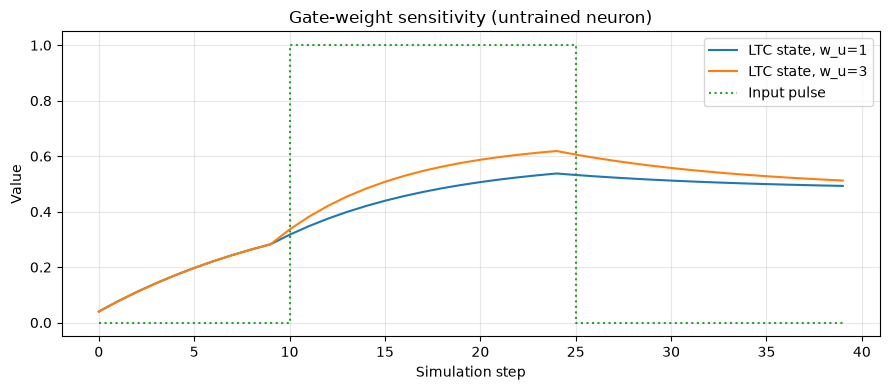

PASS: Higher input weight reduced tau_eff at ON step 10.


In [4]:
inputs_40 = torch.tensor([1.0 if 10 <= t < 25 else 0.0 for t in range(40)])
m1 = LiquidNeuron()
m3 = LiquidNeuron()
with torch.no_grad():
    m3.w_u.fill_(3.0)
    s1, g1, te1, _ = rollout(m1, inputs_40)
    s3, g3, te3, _ = rollout(m3, inputs_40)

print(" w_u | step | input | gate | tau_eff | hidden_state")
for label, g, te, s in [(1.0, g1, te1, s1), (3.0, g3, te3, s3)]:
    for t in [9, 10, 24, 25]:
        print(f" {label:3.0f} | {t:4d} | {inputs_40[t].item():5.0f} | {g[t].item():.4f} | {te[t].item():.4f} | {s[t].item():.4f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(s1.numpy(), label="LTC state, w_u=1")
ax.plot(s3.numpy(), label="LTC state, w_u=3")
ax.step(range(40), inputs_40.numpy(), where="post", linestyle=":", label="Input pulse")
ax.set(xlabel="Simulation step", ylabel="Value", title="Gate-weight sensitivity (untrained neuron)")
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUT / "01_gate_weight_sensitivity.png", dpi=150)
plt.show()

assert te3[10] < te1[10]
print("PASS: Higher input weight reduced tau_eff at ON step 10.")

## 4. Training with backpropagation through time (Chapter 6.3)

**Task:** learn a known first-order smoothing rule on two ON/OFF pulses.

$$y_{t+1}=0.85y_t+0.15u_t.$$

The target is synthetic; it is not a real-world dataset. The loss is mean squared error:

$$\mathrm{MSE}=\frac{1}{T}\sum_{t=1}^{T}(\hat y_t-y_t)^2.$$

Key distinction: keep autograd enabled for the model's unrolled recurrent trajectory. Use `.backward()` to accumulate gradients through earlier state transitions, then `optimizer.step()` to update weights.

In [5]:
def smoothing_target(input_sequence, alpha=0.15):
    y = torch.tensor(0.0)
    target = []
    for u in input_sequence:
        y = (1.0 - alpha) * y + alpha * u
        target.append(y)
    return torch.stack(target)


train_inputs = torch.zeros(80)
train_inputs[10:30] = 1.0
train_inputs[45:65] = 1.0
train_targets = smoothing_target(train_inputs)

trained = LiquidNeuron()
optimizer = torch.optim.Adam(trained.parameters(), lr=0.03)
ltc_history = []

for epoch in range(201):
    predictions, _, _, _ = rollout(trained, train_inputs)
    loss = ((predictions - train_targets) ** 2).mean()

    optimizer.zero_grad()
    loss.backward()  # BPTT through all 80 recurrent updates
    nn.utils.clip_grad_norm_(trained.parameters(), 1.0)
    optimizer.step()

    ltc_history.append(loss.item())
    if epoch % 50 == 0:
        print(f"Epoch {epoch:3d} | LTC train MSE: {loss.item():.6f}")

print("Learned tau:", round(torch.exp(trained.log_tau).item(), 6))
print("Learned w_u:", round(trained.w_u.item(), 6))
print("Learned w_x:", round(trained.w_x.item(), 6))
print("Learned A:", round(trained.A.item(), 6))
assert ltc_history[-1] < 0.005, "LTC did not fit the synthetic task; inspect training"

Epoch   0 | LTC train MSE: 0.075411
Epoch  50 | LTC train MSE: 0.016003
Epoch 100 | LTC train MSE: 0.001831
Epoch 150 | LTC train MSE: 0.000255
Epoch 200 | LTC train MSE: 0.000158
Learned tau: 0.54699
Learned w_u: 3.28261
Learned w_x: 1.938196
Learned A: 3.17193


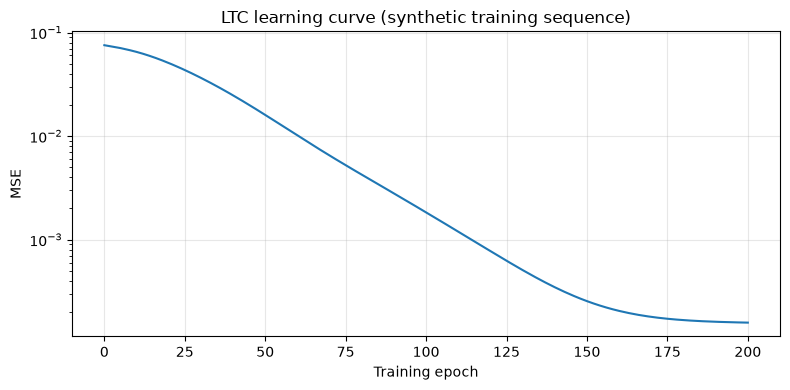

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ltc_history)
ax.set(xlabel="Training epoch", ylabel="MSE", title="LTC learning curve (synthetic training sequence)")
ax.set_yscale("log")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUT / "02_ltc_training_loss.png", dpi=150)
plt.show()

## 5. Unseen pulse sequence: what generalizes?

We keep the **same underlying smoothing law** and change the input pulse durations. This is a within-task generalization sanity check, not evidence for arbitrary out-of-distribution robustness or superiority to another architecture.

Train MSE (after final optimizer step): 0.000158
Unseen-pulse test MSE:             0.000141


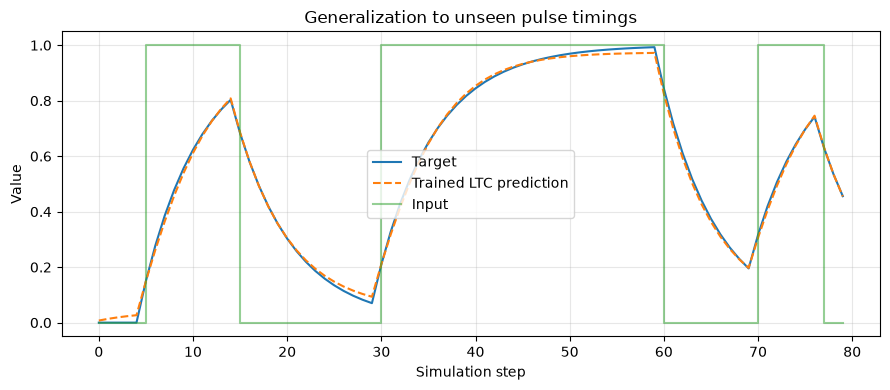

In [7]:
test_inputs = torch.zeros(80)
test_inputs[5:15] = 1.0
test_inputs[30:60] = 1.0
test_inputs[70:77] = 1.0
test_targets = smoothing_target(test_inputs)

trained.eval()
with torch.no_grad():
    train_pred, _, _, _ = rollout(trained, train_inputs)
    test_pred, _, _, _ = rollout(trained, test_inputs)
    ltc_train_mse = ((train_pred - train_targets) ** 2).mean().item()
    ltc_test_mse = ((test_pred - test_targets) ** 2).mean().item()

print(f"Train MSE (after final optimizer step): {ltc_train_mse:.6f}")
print(f"Unseen-pulse test MSE:             {ltc_test_mse:.6f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(test_targets.numpy(), label="Target")
ax.plot(test_pred.numpy(), "--", label="Trained LTC prediction")
ax.step(range(80), test_inputs.numpy(), where="post", alpha=0.5, label="Input")
ax.set(xlabel="Simulation step", ylabel="Value", title="Generalization to unseen pulse timings")
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUT / "03_unseen_pulse_test.png", dpi=150)
plt.show()

## 6. Essential baseline: trainable exponential smoother

**Research honesty check:** the synthetic targets were *generated by a first-order exponential smoother*. A **single-parameter model** can represent them exactly. Any claim that the LTC is necessarily better for this task would be unjustified.

Train that simpler baseline under the same input sequences, target, optimizer and number of epochs. Compare final train and test MSE. This isn't a fully matched research benchmark—parameter counts differ deliberately to illustrate model simplicity.

Learned EMA alpha: 0.149998 (true target alpha: 0.15)
Model           | parameters | train MSE | test MSE
LTC-style       |          5 | 0.00015758 | 0.00014072
Trainable EMA   |          1 | 0.00000000 | 0.00000000


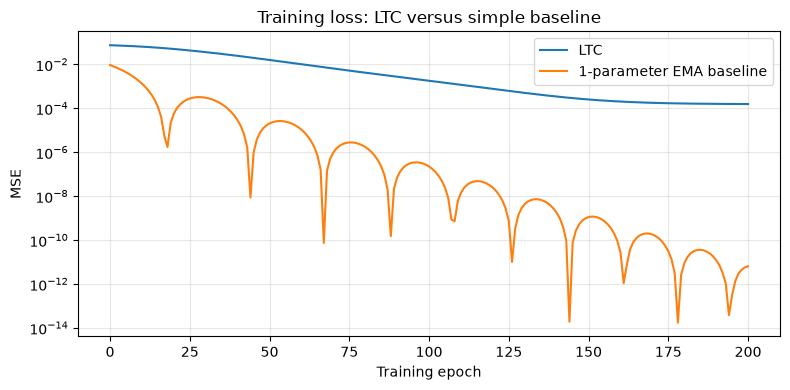

In [8]:
class TrainableEMA(nn.Module):
    def __init__(self, initial_alpha=0.1):
        super().__init__()
        self.logit_alpha = nn.Parameter(torch.tensor(math.log(initial_alpha / (1 - initial_alpha))))

    def forward(self, y, u):
        alpha = torch.sigmoid(self.logit_alpha)
        return (1 - alpha) * y + alpha * u


def ema_rollout(model, inputs):
    y = torch.tensor(0.0)
    ys = []
    for u in inputs:
        y = model(y, u)
        ys.append(y)
    return torch.stack(ys)

ema = TrainableEMA()
ema_opt = torch.optim.Adam(ema.parameters(), lr=0.03)
ema_history = []
for epoch in range(201):
    pred = ema_rollout(ema, train_inputs)
    loss = ((pred - train_targets) ** 2).mean()
    ema_opt.zero_grad()
    loss.backward()
    ema_opt.step()
    ema_history.append(loss.item())

ema.eval()
with torch.no_grad():
    ema_train_pred = ema_rollout(ema, train_inputs)
    ema_test_pred = ema_rollout(ema, test_inputs)
    ema_train_mse = ((ema_train_pred - train_targets) ** 2).mean().item()
    ema_test_mse = ((ema_test_pred - test_targets) ** 2).mean().item()

print(f"Learned EMA alpha: {torch.sigmoid(ema.logit_alpha).item():.6f} (true target alpha: 0.15)")
print("Model           | parameters | train MSE | test MSE")
print(f"LTC-style       | {sum(p.numel() for p in trained.parameters()):10d} | {ltc_train_mse:.8f} | {ltc_test_mse:.8f}")
print(f"Trainable EMA   | {sum(p.numel() for p in ema.parameters()):10d} | {ema_train_mse:.8f} | {ema_test_mse:.8f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ltc_history, label="LTC")
ax.plot(ema_history, label="1-parameter EMA baseline")
ax.set(xlabel="Training epoch", ylabel="MSE", title="Training loss: LTC versus simple baseline")
ax.set_yscale("log")
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUT / "04_baseline_comparison.png", dpi=150)
plt.show()

## 7. Numerical integration stability (Chapter 6.4)

Freeze the gate at $f=0.5$, let $\tau=2$, $A=1$, and begin from $x_0=0$.

$$\dot x=0.5-x,\qquad x(t)=0.5(1-e^{-t}).$$

The equilibrium is $x^*=0.5$. For explicit Euler, the error multiplier is $1-h$. Thus convergence requires $|1-h|<1$, i.e. $0<h<2$ for **this specific system**. RK4 uses four slope evaluations per step and has a different stability region: it is not universally stable or always computationally preferable.

In [9]:
def rhs(x):
    return 0.5 - x

def euler(x, h):
    return x + h * rhs(x)

def rk4(x, h):
    k1 = rhs(x)
    k2 = rhs(x + h * k1 / 2)
    k3 = rhs(x + h * k2 / 2)
    k4 = rhs(x + h * k3)
    return x + h * (k1 + 2*k2 + 2*k3 + k4) / 6

def exact(t):
    return 0.5 * (1 - math.exp(-t))

stability_results=[]
for h in [0.1, 1.0, 2.0, 2.5]:
    xe, xr = 0.0, 0.0
    for _ in range(8):
        xe = euler(xe, h)
        xr = rk4(xr, h)
    ex = exact(8 * h)
    stability_results.append((h, xe, xr, ex, abs(xe-ex), abs(xr-ex)))

print("h    | Euler x_8    | RK4 x_8      | exact        | Euler error  | RK4 error")
for h, xe, xr, ex, err_e, err_r in stability_results:
    print(f"{h:3.1f}  | {xe:12.5f} | {xr:12.5f} | {ex:12.5f} | {err_e:12.5f} | {err_r:.5f}")

assert abs(stability_results[-1][1] - (-12.314453125)) < 1e-5
assert abs(stability_results[-1][2] - 0.48437) < 1e-4

h    | Euler x_8    | RK4 x_8      | exact        | Euler error  | RK4 error
0.1  |      0.28477 |      0.27534 |      0.27534 |      0.00943 | 0.00000
1.0  |      0.50000 |      0.49980 |      0.49983 |      0.00017 | 0.00003
2.0  |      0.00000 |      0.49992 |      0.50000 |      0.50000 | 0.00008
2.5  |    -12.31445 |      0.48437 |      0.50000 |     12.81445 | 0.01563


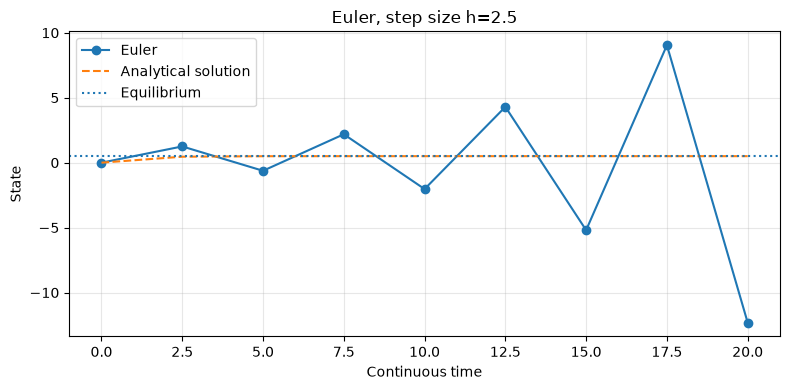

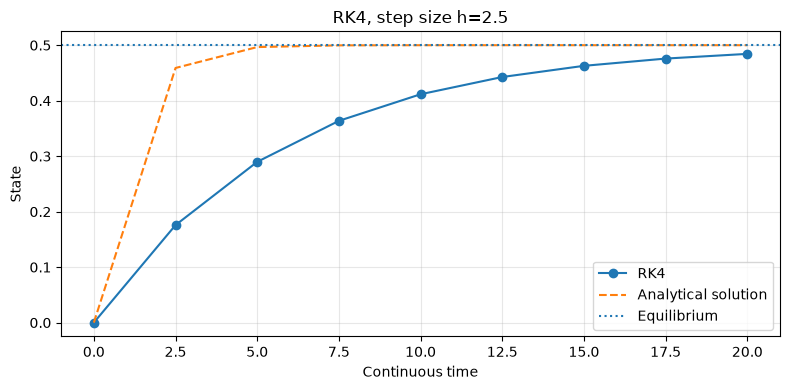

In [10]:
h = 2.5
times = np.arange(9) * h
es, rs = [0.0], [0.0]
for _ in range(8):
    es.append(euler(es[-1], h))
    rs.append(rk4(rs[-1], h))
truth = [exact(t) for t in times]

for title, values, filename in [
    ("Euler", es, "05_euler_stability.png"),
    ("RK4", rs, "06_rk4_stability.png")
]:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(times, values, "o-", label=title)
    ax.plot(times, truth, "--", label="Analytical solution")
    ax.axhline(0.5, linestyle=":", label="Equilibrium")
    ax.set(xlabel="Continuous time", ylabel="State", title=f"{title}, step size h=2.5")
    ax.legend(); ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(OUT / filename, dpi=150)
    plt.show()

## 8. Advanced sanity check: the nonlinear gate changes local stability

For the educational LTC vector field $F(x,u)$, local stability depends on the derivative

$$
\frac{\partial F}{\partial x}
=-\frac{1}{\tau}-f(x,u)+\frac{\partial f}{\partial x}(A-x),
\quad \frac{\partial f}{\partial x}=w_xf(1-f).
$$

We check this analytical derivative against PyTorch autograd. This is a **local derivative check**, not a proof of global stability.

In [11]:
check_model = LiquidNeuron()
x_local = torch.tensor(0.5, requires_grad=True)
u_local = torch.tensor(1.0)
tau_local = torch.exp(check_model.log_tau)
gate_local = torch.sigmoid(check_model.w_x * x_local + check_model.w_u * u_local + check_model.bias)
F = -x_local / tau_local + gate_local * (check_model.A - x_local)
autograd_dFdx = torch.autograd.grad(F, x_local)[0]
formula_dFdx = -1 / tau_local - gate_local + check_model.w_x * gate_local * (1-gate_local) * (check_model.A - x_local)

print(f"dF/dx via autograd: {autograd_dFdx.item():.8f}")
print(f"dF/dx via formula:  {formula_dFdx.item():.8f}")
assert torch.allclose(autograd_dFdx, formula_dFdx, atol=1e-7)
print("PASS: local Jacobian derivative agrees with autograd")

dF/dx via autograd: -1.14686155
dF/dx via formula:  -1.14686155
PASS: local Jacobian derivative agrees with autograd


## 9. Export evidence and write the chapter memo

We save machine-readable metrics and a reproducible artifact bundle in the working directory. **Record conclusions supported by results, not impressions from attractive plots.**

In [ ]:
with (OUT / "training_loss.csv").open("w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["epoch", "ltc_train_mse", "ema_train_mse"])
    writer.writerows((i, ltc_history[i], ema_history[i]) for i in range(201))

with (OUT / "summary_metrics.csv").open("w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["model", "num_parameters", "train_mse", "test_mse"])
    writer.writerow(["scalar_ltc_style", 5, ltc_train_mse, ltc_test_mse])
    writer.writerow(["trainable_ema", 1, ema_train_mse, ema_test_mse])

with (OUT / "solver_results.csv").open("w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["step_size", "euler_after_8", "rk4_after_8", "exact", "euler_abs_err", "rk4_abs_err"])
    writer.writerows(stability_results)

print("Saved:")
for p in sorted(OUT.iterdir()):
    print(" -", p)

Saved:
 - chapter6_outputs/01_gate_weight_sensitivity.png
 - chapter6_outputs/02_ltc_training_loss.png
 - chapter6_outputs/03_unseen_pulse_test.png
 - chapter6_outputs/04_baseline_comparison.png
 - chapter6_outputs/05_euler_stability.png
 - chapter6_outputs/06_rk4_stability.png
 - chapter6_outputs/solver_results.csv
 - chapter6_outputs/summary_metrics.csv
 - chapter6_outputs/training_loss.csv


: 

### Chapter 6 — Final Research Memo

**Question:** What does a learned input-varying gate change relative to a fixed-coefficient recurrence?

**Answer:** A learned input-varying gate allows the neuron's effective time constant and state evolution to change according to its current input and hidden state. Unlike a fixed-coefficient recurrence, an LTC-style neuron can adapt its response dynamics instead of always using the same update coefficient.

**Mechanism:** A scalar gated continuous-time state equation, numerically advanced using Euler integration.

- LTC dynamics: `dx/dt = -x/τ + f(x,u)(A-x)`
- Gate: `f(x,u) = sigmoid(w_x*x + w_u*u + b)`
- Effective time constant: `τ_eff = τ/(1 + τ*f)`
- Euler update: `x_next = x + dt*dxdt`

**Training setup:**

- Dataset: 80-step synthetic pulse sequence
- Target: First-order exponential smoothing (EMA)
- Training: 201 epochs, Adam optimizer
- Learning rate: 0.03
- Random seed: 42
- Hardware: CPU
- Loss function: Mean Squared Error (MSE)
- Training method: Backpropagation Through Time (BPTT)

**Results:**

| Metric | Result |
|---|---|
| Initial training MSE | 0.075411 |
| Final training MSE | 0.000158 |
| Unseen-sequence test MSE | 0.000141 |
| Training error reduction | Approximately 99.79% |
| LTC-style model parameters | 5 |
| EMA baseline parameters | 1 |
| EMA baseline test MSE | Approximately 0 |

The trained LTC-style neuron closely approximated the target signal on an unseen pulse sequence. However, the test sequence used the same smoothing law as the training sequence, with different pulse timings.

**Baseline:** A one-parameter trainable Exponential Moving Average (EMA) reproduced the target almost exactly. Since the target itself was generated by a fixed-coefficient EMA, the simpler model had a natural advantage.

This experiment does not establish LTC superiority. It demonstrates the importance of selecting strong, task-appropriate baselines.

**Numerical method:** For the frozen-gate linear case, explicit Euler diverged at `h = 2.5`, while RK4 remained bounded but was less accurate than the analytical solution. At smaller step sizes, both methods approximated the analytical trajectory.

A stable continuous-time system can produce unstable numerical predictions when the integration step size violates the solver's stability conditions.

**Limitations:** This experiment uses a simplified scalar LTC-style neuron, synthetic targets, one random seed, and one training sequence. It is not a faithful implementation of the complete multi-neuron LTC architecture. No matched RNN/GRU benchmark, real-world dataset, inference-speed comparison, memory measurement, or energy evaluation was performed.

**Research decision — UNKNOWN:**

The LTC-style neuron successfully demonstrated learnable temporal dynamics and generalization to new pulse timings. However, its architectural advantage remains unproven because a simpler one-parameter EMA performed better on this particular synthetic task.

The adaptive liquid mechanism is worth investigating further, but no superiority or edge-efficiency claim is justified yet.

**Next falsifiable question:**

Does an LTC-style neuron achieve lower test error than fixed-coefficient recurrent baselines on sequences requiring input-dependent response speeds, under comparable training and computational budgets?

**Hypothesis:** Input-adaptive continuous-time dynamics may improve prediction when a sequence requires its response speed to change dynamically.

**Proposed future experiment:** Generate sequences with input-dependent smoothing rates and compare LTC-style, EMA, vanilla RNN and GRU models. Evaluate test MSE, parameter count, runtime, memory consumption and performance across multiple random seeds.

---

### Chapter 6 — Checkpoint Questions and Answers

**1. Why is `tau = exp(log_tau)` preferable to an unconstrained parameter named `tau`?**

The time constant must remain positive for the intended LTC dynamics. Storing `log_tau` as a trainable parameter and applying `exp()` guarantees `tau > 0`, even when the optimizer updates its underlying parameter. Directly optimizing an unconstrained `tau` could result in zero or negative values, causing division problems or unintended dynamics.

**2. Why does the gate still influence state evolution when the external input is zero?**

The gate depends on both the hidden state and the input:

`f(x,u) = sigmoid(w_x*x + w_u*u + b)`

When `u = 0`, the input-weight contribution disappears, but the hidden-state contribution and bias remain. Therefore, the gate can remain active and continue influencing the neuron's state evolution.

**3. Why can a stable ODE produce an unstable Euler trajectory?**

Continuous-time stability does not guarantee numerical stability. Euler integration approximates the solution using finite steps. If the step size is too large, its discrete updates can amplify errors instead of reducing them.

For the test equation `dx/dt = -kx`, explicit Euler is asymptotically stable only when `0 < hk < 2`, assuming `k > 0`.

Our experiment verified this: with `k = 1` and `h = 2.5`, Euler diverged even though the analytical solution converged.

**4. Why does near-perfect fitting on this toy task not establish that an LTC is preferable to a one-parameter filter?**

The target was generated using a fixed-coefficient EMA. Therefore, a one-parameter EMA can represent the generating process exactly, while the LTC-style neuron uses five parameters to approximate it.

Low training or test error on this synthetic task demonstrates successful fitting, not architectural superiority. We need more demanding tasks, multiple datasets and fair comparisons with alternative models.

**5. Which additional measurements and architecture baselines are needed before claiming an edge-efficiency advantage?**

Required architecture baselines include EMA, vanilla RNN, GRU/LSTM, and appropriate LTC/CfC or other sequence-model comparators.

Required measurements include:

- Test accuracy or MSE on relevant datasets
- Model parameter count and model size
- Inference latency and sustained throughput
- Peak memory usage and recurrent-state memory
- Computational cost and numerical-solver overhead
- Energy consumption and thermal behavior on target hardware
- Multiple-seed experiments and uncertainty estimates

All architectures must be evaluated under comparable training conditions and resource budgets. Edge advantages must be demonstrated on actual target hardware rather than inferred from architecture alone.

---

### Final Chapter 6 Conclusion

Chapter 6 established a working foundation in liquid time-constant dynamics, recurrent neural-network implementation, BPTT training, generalization testing, baseline comparison and numerical stability.

The experiments demonstrate that an LTC-style neuron can learn smooth temporal responses, but they do not establish superiority over simpler recurrent systems.

**Research status:** Educational implementation and experimental sanity checks completed.

**Next:** Chapter 7 — Closed-form Continuous-time Neural Networks (CfC).

**Formal LTC/CfC paper reproduction:** Chapter 8.

**References:**

Hasani et al., [Liquid Time-constant Networks](https://arxiv.org/abs/2006.04439), AAAI 2021.

FlowState Research Curriculum v2.0, Chapter 6, October 2026.